## 🐻‍❄️ 투빅스 25&26기 - 추천시스템 & GNN 과제 [MovieLens로 BPR-MF, NeuMF, LightGCN 직접 구현]

#### ✅ 과제 목적
세션에서 배운 추천의 흐름 - **시청 기록 → 평가 지표 → 벡터(임베딩)로 학습 → 그래프로 연결 전파** - 를 실제 데이터로 따라갑니다.
라이브러리의 완성된 모델을 불러오는 대신, 세션 슬라이드에 나온 **식을 직접 코드로 옮겨** 네 가지 추천 방법을 같은 조건에서 비교합니다.

> - **Part A. 직접 구현하고 비교하기 (필수)** - 평가 지표, 인기순, Item-CF, BPR-MF, NeuMF, LightGCN을 차례로 구현하고 Recall@20, NDCG@20으로 비교합니다.
> - **Part B. 세션의 주장을 검증하기 (심화 선택)** - "층은 깊을수록 좋은가?", "W와 σ를 빼니 더 좋아졌다", "정규화가 인기 편향을 줄이는가?"를 본인 실험으로 확인합니다.

#### 📝 기술블로그 활용 방안 (필수 확인)
이 과제의 실험, 코드, 해석은 **기술블로그 글의 재료**입니다. 아래 항목은 노트북에서 끝내지 말고 **기술블로그에 옮겨 작성**해 주세요.

| 블로그에 옮길 내용 | 노트북 위치 |
|---|---|
| ① MovieLens의 희소성 수치와 Long-tail 그래프, 그리고 "빈칸 = 모름"에 대한 본인 해석 | 1장, 서술형 문제 1 |
| ② 직접 구현한 Recall@K, NDCG@K 코드와, 세션 예시(0.40 / 0.67 / 0.70)로 검증한 과정 | 2장 |
| ③ BPR 손실, Negative Sampling, LightGCN 정규화, 전파 코드를 **식과 함께** 설명 | 4장, 6장 |
| ④ **네 모델 비교 표, 막대그래프와 해석** (가장 중요) | 7장, 서술형 문제 2, 3 |
| ⑤ (심화 선택) 층 수 실험, W/σ 실험, 인기 편향 실험의 그래프와, 세션 주장과 **같았는지 / 달랐는지**에 대한 해석 | Part B, 서술형 문제 4, 5, 6 |

> 블로그에는 **본인 시드로 나온 숫자와 그래프를 그대로** 쓰고, 결과가 세션 슬라이드와 다르게 나왔다면 그 이유를 추론해 함께 적어 주세요.

> **데이터셋:** [MovieLens-100K](https://grouplens.org/datasets/movielens/100k/) (GroupLens) - [RecBole 저장소](https://github.com/RUCAIBox/RecBole)의 사본을 내려받아 사용합니다.
> - 사용자 943명, 영화 1,682편, 별점 100,000개
> - 세션처럼 **암묵적 피드백**으로 바꿔 씁니다: 별점 4점 이상 = "봤다(좋아했다)", 나머지와 기록 없음 = 빈칸

#### ✅ 주의 사항
- **런타임 > 런타임 유형 변경 > GPU**를 켜고 시작하세요. (CPU로도 돌아가지만 Part B가 느립니다)
- `# ===== TODO n =====` 블록 안만 채우세요. 나머지 셀은 준비 코드이므로 수정하지 않습니다.
- `MY_SEED`(학번 뒷 4자리)에 따라 데이터 분할이 달라져 **사람마다 숫자가 조금씩 다릅니다.** 정상입니다.
- 각 TODO 아래의 `✅ 확인` 셀이 통과해야 다음으로 넘어갈 수 있습니다.

### 🗺️ 실습 흐름

> **Part A. 직접 구현하고 비교하기 (필수)**
0. 환경 설정
1. 데이터 만나기 - 상호작용 행렬, Sparsity, Long-tail
2. 채점 방법 만들기 - Recall@K, NDCG@K 직접 구현
3. 기준 모델 - 인기순 추천, Item-CF (Jaccard)
4. BPR-MF - 내적 점수, Negative Sampling, BPR 손실
5. NeuMF - 내적 대신 신경망
6. LightGCN - 정규화 인접행렬, 층별 전파, 층 평균
7. 네 모델 비교 + 내 시드의 사용자에게 추천된 영화 보기

> **Part B. 세션의 주장을 검증하기 (심화 선택)**
8. 층은 깊을수록 좋을까? - 층 수 실험 & Over-smoothing 측정
9. W와 σ를 다시 넣으면? - LightGCN vs NGCF 스타일
10. 정규화는 인기 편향을 줄일까? - 추천 결과의 인기도 분석

### 📖 세션 슬라이드 대응표

| 노트북 | 세션 슬라이드 |
|---|---|
| 1장 상호작용 행렬, Sparsity, Long-tail | 6~8p 데이터 이해하기, 14p 추천의 어려움 |
| 2장 Recall@K, NDCG@K | 9p 평가 방법 |
| 3장 인기순, Item-CF | 13p Item-based CF (Jaccard), 14p 인기 편향 |
| 4장 BPR-MF | 17~18p MF와 내적, 20p BPR과 Negative Sampling |
| 5장 NeuMF | 21p NCF |
| 6장 LightGCN | 25p 이분 그래프, 39~40p LightGCN 동작 방식 |
| 8장 층 수, Over-smoothing | 31p Over-smoothing, 41p 층 수 실험 |
| 9장 W와 σ | 33p GCN, 38p NGCF → LightGCN |
| 10장 인기 편향 | 14p 인기 편향, 39p 정규화 |

# 🧭 Part A. 직접 구현하고 비교하기 (필수)

### ⚙️ 0. 환경 설정 - 라이브러리, 학생별 시드, 실험 설정

In [2]:
import os, math, random, time, urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # torch sparse 경고 숨김

# ---- 실험 설정 (모든 모델이 같은 조건) ----
EMB_DIM = 64          # 임베딩 길이
TOPK = 20             # Recall@20, NDCG@20
EPOCHS = 50          # 모델별 학습 epoch
BATCH_SIZE = 2048
LR = 5e-3
REG = 1e-4            # 임베딩 L2 정규화 계수
N_LAYERS = 3          # LightGCN 기본 층 수
POS_THRESHOLD = 4     # 별점 4점 이상 = 상호작용(봤다)

# ===== TODO 0 =====
# 힌트: 본인 학번 뒷 4자리를 넣으세요. (예: 202612345 -> 2345)
MY_SEED = 9029   # TODO: 학번 뒷 4자리
# ==================

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

assert MY_SEED is not None, "TODO 0: MY_SEED에 학번 뒷 4자리를 넣으세요."
set_seed(MY_SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device  :", device)
print("MY_SEED :", MY_SEED)
if device == "cpu":
    print("\n⚠️ GPU가 아닙니다. 런타임 > 런타임 유형 변경에서 GPU를 켜세요.")

device  : cuda
MY_SEED : 9029


### 📦 1. 데이터 만나기 - 상호작용 행렬, Sparsity, Long-tail

세션 7p처럼 시청 기록을 **사용자 × 영화 표**로 바꿉니다. 별점 4점 이상만 "봤다(1)"로 남기고, 나머지는 빈칸입니다.

In [3]:
# ---- MovieLens-100K 다운로드 (준비 코드) ----
# GroupLens 원본과 같은 데이터를 RecBole 공식 저장소의 사본에서 받습니다.
# (Colab에서 GroupLens 서버는 SSL 인증서 오류로 다운로드가 실패하는 경우가 있습니다)
BASE = "https://raw.githubusercontent.com/RUCAIBox/RecBole/master/dataset/ml-100k/"
for f in ["ml-100k.inter", "ml-100k.item"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

ratings = pd.read_csv("ml-100k.inter", sep="\t")
ratings.columns = ["user", "item", "rating", "ts"]
titles = pd.read_csv("ml-100k.item", sep="\t", usecols=[0, 1])
titles.columns = ["item", "title"]

# 암묵적 피드백으로 변환: 별점 4점 이상만 상호작용으로 사용
inter = ratings[ratings.rating >= POS_THRESHOLD][["user", "item"]].drop_duplicates()

# 사용자 / 영화 번호를 0부터 다시 매기기
uid = {u: k for k, u in enumerate(sorted(inter.user.unique()))}
iid = {i: k for k, i in enumerate(sorted(inter.item.unique()))}
inter = inter.assign(u=inter.user.map(uid), i=inter.item.map(iid))
idx2title = dict(zip(titles.item.map(iid), titles.title))
n_users, n_items = len(uid), len(iid)

print("원본 별점 수        :", len(ratings))
print("상호작용 수 (4점↑) :", len(inter))
print("사용자 수 × 영화 수 : %d × %d" % (n_users, n_items))

원본 별점 수        : 100000
상호작용 수 (4점↑) : 55375
사용자 수 × 영화 수 : 942 × 1447


#### ✏️ ===== TODO 1 =====
세션 8p처럼 **빈칸 비율(Sparsity)** 을 구하세요. Sparsity = 1 − (상호작용 수 ÷ 전체 칸 수)

In [4]:
# ===== TODO 1 =====
# 힌트: 전체 칸 수 = n_users * n_items
sparsity = 1 - len(inter) / (n_users * n_items)   # TODO: 여기에 코드를 작성하세요
# ==================

# ✅ 확인
assert sparsity is not None and 0.9 < sparsity < 1.0, "Sparsity 계산을 다시 확인하세요."
print("Sparsity: %.2f%%  (세션 예시 MovieLens-1M은 약 95.5%%)" % (sparsity * 100))
print("✅ 통과")

Sparsity: 95.94%  (세션 예시 MovieLens-1M은 약 95.5%)
✅ 통과


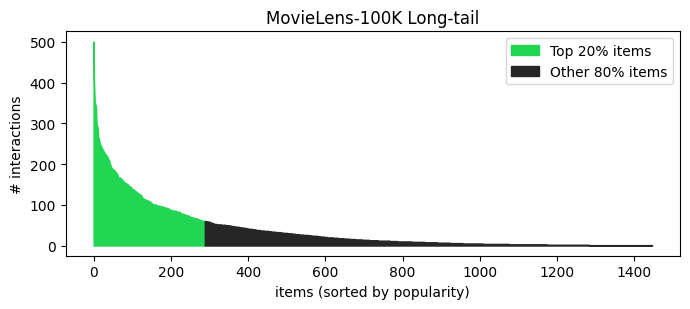

상위 20%의 영화가 전체 상호작용의 69.0%를 차지


In [5]:
# ---- Long-tail 그래프 (준비 코드) ----
item_cnt = inter.i.value_counts().sort_values(ascending=False).values
head_n = int(len(item_cnt) * 0.2)
share = item_cnt[:head_n].sum() / item_cnt.sum()

plt.figure(figsize=(7, 3.2))
plt.fill_between(range(head_n), item_cnt[:head_n], color="#22D654", label="Top 20% items")
plt.fill_between(range(head_n - 1, len(item_cnt)), item_cnt[head_n - 1:], color="#262626", label="Other 80% items")
plt.xlabel("items (sorted by popularity)"); plt.ylabel("# interactions"); plt.legend()
plt.title("MovieLens-100K Long-tail"); plt.tight_layout(); plt.show()
print("상위 20%%의 영화가 전체 상호작용의 %.1f%%를 차지" % (share * 100))

#### 📝 서술형 문제 1
1. 본인의 Sparsity 값과 Long-tail 그래프의 "상위 20% 비율"을 인용하세요.
2. 이 데이터에서 빈칸이 "싫어서 안 본 것"이 아니라 "아직 모르는 것"으로 봐야 하는 이유를, 우리가 별점 4점 미만을 **빈칸으로 처리했다**는 사실과 연결해 설명하세요. (이 처리 방식의 한계도 한 가지 적어 보세요.)

--
1. 95.94%, 69,0%
2. 상호작용 행렬에서 빈칸은 사용자가 해당 영화를 싫어한다는 의미가 아니라 긍정적인 상호작용이 관측되지 않았다는 의미이다. 이번 실험에서는 별점 4점 이상만 긍정적 상호작용으로 처리하고, 4점 미만의 평가와 평가 기록이 없는 경우를 모두 빈칸으로 처리했다.

   따라서 실제로 낮은 평점을 준 영화와 아직 평가하지 않은 영화를 구분할 수 없다는 한계가 있다. 이러한 정보 손실은 사용자의 선호를 정확하게 학습하는 데 영향을 줄 수 있다.

### 🎯 2. 채점 방법 만들기 - Recall@K, NDCG@K

세션 9p처럼 **기록 일부를 숨겨두고**(test), 모델이 추천한 상위 K개 안에 다시 나오는지 확인합니다.
분할은 사용자마다 기록의 20%를 test로 숨기며, `MY_SEED`에 따라 달라집니다.

In [6]:
# ---- train / test 분할 (준비 코드): 사용자마다 20%를 test로 ----
rng = np.random.default_rng(MY_SEED)
train_rows, test_rows = [], []
for u, g in inter.groupby("u"):
    items = g.i.values.copy(); rng.shuffle(items)
    n_test = max(1, int(round(len(items) * 0.2))) if len(items) >= 5 else 0
    test_rows += [(u, i) for i in items[:n_test]]
    train_rows += [(u, i) for i in items[n_test:]]
train_df = pd.DataFrame(train_rows, columns=["u", "i"])
test_df = pd.DataFrame(test_rows, columns=["u", "i"])

train_items = train_df.groupby("u").i.apply(set).to_dict()            # 사용자별 학습 기록
test_items = test_df.groupby("u").i.apply(set).to_dict()              # 사용자별 정답(숨긴 기록)
train_u = torch.tensor(train_df.u.values); train_i = torch.tensor(train_df.i.values)
train_mask = torch.zeros(n_users, n_items, dtype=torch.bool)   # 학습 때 본 영화면 True
train_mask[train_u, train_i] = True
print("train 상호작용: %d / test 상호작용: %d / 평가 대상 사용자: %d" % (len(train_df), len(test_df), len(test_items)))

train 상호작용: 44300 / test 상호작용: 11075 / 평가 대상 사용자: 938


#### ✏️ ===== TODO 2 =====
한 사용자의 추천 목록 `ranked`(점수 높은 순, 길이 K)와 정답 집합 `truth`로 **Recall@K**와 **NDCG@K**를 구하는 함수를 완성하세요.

- Recall@K = 상위 K개 안에서 찾은 정답 수 ÷ 정답 수
- NDCG@K = DCG ÷ IDCG,  DCG = Σ (정답이면 1) / log₂(순위 + 1),  IDCG = 정답을 모두 맨 위에 놓았을 때의 DCG

In [7]:
def recall_at_k(ranked, truth):
    # ===== TODO 2-1 =====
    # 힌트: set으로 바꿔 교집합의 크기를 세세요.
    return len(set(ranked) & set(truth)) / len(truth) if len(truth) > 0 else 0.0   # TODO: 여기에 코드를 작성하세요
    # ==================


def ndcg_at_k(ranked, truth):
    # ===== TODO 2-2 =====
    # 힌트: 순위는 1부터 시작합니다. 1등의 할인은 1/log2(2) = 1 입니다.
    # 힌트: IDCG는 정답 개수와 K 중 작은 수만큼 1/log2(r+1)을 더한 값입니다.
    dcg = dcg = sum(1 / math.log2(r + 1)
        for r, item in enumerate(ranked, start=1)
        if item in truth)    # TODO: 여기에 코드를 작성하세요
    idcg = sum(1 / math.log2(r + 1)
        for r in range(1, min(len(truth), len(ranked)) + 1))   # TODO: 여기에 코드를 작성하세요
    return dcg / idcg if idcg > 0 else 0.0   # TODO: 여기에 코드를 작성하세요
    # ==================


# ✅ 확인 - 세션 9p 예시 그대로: 정답 3개, 추천 5개 중 1등과 3등이 정답
ranked = ["매트릭스", "라라랜드", "테넷", "어바웃 타임", "아바타"]
truth = {"매트릭스", "테넷", "덩케르크"}
r, n = recall_at_k(ranked, truth), ndcg_at_k(ranked, truth)
assert r is not None and n is not None, "TODO 2를 완성하세요."
print("Recall@5 = %.2f (세션: 0.67) / NDCG@5 = %.3f (세션: 0.70)" % (r, n))
assert abs(r - 2 / 3) < 1e-6 and abs(n - 0.7039) < 1e-3, "세션 예시와 값이 다릅니다."
print("✅ 통과")

Recall@5 = 0.67 (세션: 0.67) / NDCG@5 = 0.704 (세션: 0.70)
✅ 통과


In [8]:
# ---- 전체 평가 함수 (준비 코드): 학습 때 본 영화는 후보에서 제외하고 Top-K 추출 ----
@torch.no_grad()
def evaluate(score_fn, k=TOPK, return_lists=False):
    # score_fn(user_idx_tensor) -> (len(users), n_items) 점수 행렬
    users = sorted(test_items.keys())
    recalls, ndcgs, rec_lists = [], [], {}
    for s in range(0, len(users), 256):
        batch = users[s:s + 256]
        scores = score_fn(torch.tensor(batch, device=device)).float().cpu()
        for row, u in enumerate(batch):
            seen = list(train_items.get(u, ()))
            scores[row, seen] = -float("inf")
        top = torch.topk(scores, k, dim=1).indices.numpy()
        for row, u in enumerate(batch):
            ranked = top[row].tolist()
            recalls.append(recall_at_k(ranked, test_items[u]))
            ndcgs.append(ndcg_at_k(ranked, test_items[u]))
            rec_lists[u] = ranked
    out = {"Recall@%d" % k: float(np.mean(recalls)), "NDCG@%d" % k: float(np.mean(ndcgs))}
    return (out, rec_lists) if return_lists else out

results = {}   # 모델별 결과를 모아 7장에서 비교합니다

### 📏 3. 기준 모델 - 인기순 추천, Item-CF

복잡한 모델을 만들기 전에 **기준선**부터 잽니다. 이 기준선을 못 넘으면 모델을 쓸 이유가 없습니다.

#### ✏️ ===== TODO 3 =====
**인기순 추천**: 모든 사용자에게 학습 데이터에서 가장 많이 본 영화부터 추천합니다. 영화별 상호작용 수 `pop`을 구하세요.

In [9]:
# ===== TODO 3 =====
# 힌트: train_i 에서 영화 번호별 등장 횟수를 세세요. (torch.bincount, minlength=n_items)
pop = torch.bincount(train_i, minlength=n_items).float()   # TODO: 여기에 코드를 작성하세요
# ==================

assert pop is not None, "TODO 3을 완성하세요."
results["Popularity"] = evaluate(lambda users: pop.to(device).unsqueeze(0).repeat(len(users), 1))
print(results["Popularity"])

{'Recall@20': 0.18571650276390064, 'NDCG@20': 0.16975192979671985}


#### ✏️ ===== TODO 4 =====
세션 13p의 **Item-CF (Jaccard)** 입니다. 두 영화를 모두 본 사람 수 ÷ 둘 중 하나라도 본 사람 수.

`R`은 사용자 × 영화 0/1 행렬입니다. `co = Rᵀ R`의 (a, b) 칸은 a와 b를 **모두 본 사람 수**입니다.
사용자 점수는 "내가 본 영화들과의 Jaccard 유사도 합"으로 계산합니다.

In [20]:
R = torch.zeros(n_users, n_items)
R[train_u, train_i] = 1.0
co = R.T @ R                      # (n_items, n_items) 모두 본 사람 수
deg = R.sum(0)                    # 영화별 본 사람 수

# ===== TODO 4 =====
# 힌트: 둘 중 하나라도 본 사람 수 = deg[a] + deg[b] - co[a, b]  (브로드캐스팅 활용)
# 힌트: 0으로 나누지 않도록 분모에 clamp(min=1)을 쓰고, 자기 자신과의 유사도(대각선)는 0으로 두세요.
union = deg[:, None] + deg[None, :] - co     # TODO: 여기에 코드를 작성하세요
jaccard = co / union.clamp(min=1)   # TODO: 여기에 코드를 작성하세요

# ==================

assert jaccard is not None, "TODO 4를 완성하세요."
R_dev, J_dev = R.to(device), jaccard.to(device)
results["Item-CF"] = evaluate(lambda users: R_dev[users] @ J_dev)
print(results["Item-CF"])

{'Recall@20': 0.28405071991385783, 'NDCG@20': 0.2650130013594082}


### 🧠 4. BPR-MF - 내적 점수, Negative Sampling, BPR 손실

세션 18p, 20p를 그대로 코드로 옮깁니다.
- 점수: **ŷ = 사용자 벡터와 영화 벡터의 내적**
- 학습: 시청 기록에는 '싫어요'가 없으므로, **본 영화(pos)를 안 본 영화(neg)보다 선호한다고 가정**하고 순서를 학습합니다.
- `L = − mean( ln σ(ŷ_pos − ŷ_neg) )` (+ 임베딩 L2 정규화)

#### ✏️ ===== TODO 5, 6, 7 =====

In [24]:
def sample_batch(batch_size):
    # 학습 상호작용에서 (user, pos)를 뽑고, 각 user가 보지 않은 영화를 neg로 하나씩 뽑습니다.
    idx = torch.randint(0, len(train_u), (batch_size,))
    users, pos = train_u[idx], train_i[idx]
    # ===== TODO 5 =====
    # 힌트: Negative Sampling: 무작위 영화를 뽑되, 그 사용자가 학습 때 본 영화(train_mask[users, neg]가 True)면 그 자리만 다시 뽑으세요.
    # 힌트: neg는 '싫어한 영화'가 아니라 학습용 비교 대상입니다.
    neg = torch.randint(0, n_items, (batch_size,))   # TODO: 여기에 코드를 작성하세요
    invalid = train_mask[users, neg]

    while invalid.any().item():
        neg[invalid] = torch.randint(0, n_items, (invalid.sum().item(),))
        invalid = train_mask[users, neg]
    # ==================
    return users.to(device), pos.to(device), neg.to(device)


def bpr_loss(pos_score, neg_score):
    # ===== TODO 6 =====
    # 힌트: F.logsigmoid 를 쓰면 수치적으로 안정적입니다.
    return - F.logsigmoid(pos_score - neg_score).mean()   # TODO: 여기에 코드를 작성하세요
    # ==================


class MF(nn.Module):
    def __init__(self):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, EMB_DIM)
        self.item_emb = nn.Embedding(n_items, EMB_DIM)
        nn.init.normal_(self.user_emb.weight, std=0.1)
        nn.init.normal_(self.item_emb.weight, std=0.1)

    def score(self, users, items):
        # users, items 는 같은 길이의 번호 텐서. 각 쌍의 점수를 돌려줍니다.
        # ===== TODO 7 =====
        # 힌트: 세션 18p: 두 벡터의 내적 = 같은 위치끼리 곱해서 더하기
        return (self.user_emb(users) * self.item_emb(items)).sum(dim=-1)   # TODO: 여기에 코드를 작성하세요
        # ==================

    def full_scores(self, users):
        return self.user_emb(users) @ self.item_emb.weight.T

    def reg(self, users, pos, neg):
        return (self.user_emb(users).pow(2).sum() + self.item_emb(pos).pow(2).sum() + self.item_emb(neg).pow(2).sum()) / len(users)

In [25]:
# ---- 공통 학습 루프 (준비 코드): 모든 모델을 같은 BPR, 같은 epoch로 학습 ----
def train_model(model, epochs=EPOCHS, verbose=True):
    set_seed(MY_SEED)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    steps = max(1, len(train_u) // BATCH_SIZE)
    curve = []
    for ep in range(1, epochs + 1):
        model.train(); total = 0.0
        for _ in range(steps):
            u, p, n = sample_batch(BATCH_SIZE)
            loss = bpr_loss(model.score(u, p), model.score(u, n)) + REG * model.reg(u, p, n)
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item()
        if ep % 10 == 0 or ep == epochs:
            model.eval(); m = evaluate(model.full_scores); curve.append((ep, m["Recall@%d" % TOPK]))
            if verbose:
                print("epoch %3d | loss %.4f | Recall@%d %.4f | NDCG@%d %.4f" % (ep, total / steps, TOPK, m["Recall@%d" % TOPK], TOPK, m["NDCG@%d" % TOPK]))
    model.eval()
    return model, curve

# ✅ 확인
u, p, n = sample_batch(512)
assert all(n[k].item() not in train_items[u[k].item()] for k in range(512)), "neg 중에 사용자가 본 영화가 섞여 있습니다."
assert abs(bpr_loss(torch.tensor([2.0]), torch.tensor([0.0])).item() - 0.1269) < 1e-3, "BPR 손실 식을 확인하세요."
print("✅ 통과")

t0 = time.time()
mf, _ = train_model(MF())
results["BPR-MF"] = evaluate(mf.full_scores)
print("BPR-MF:", results["BPR-MF"], "(%.0f초)" % (time.time() - t0))

✅ 통과
epoch  10 | loss 0.1949 | Recall@20 0.2952 | NDCG@20 0.2619
epoch  20 | loss 0.1067 | Recall@20 0.3207 | NDCG@20 0.2818
epoch  30 | loss 0.0741 | Recall@20 0.3171 | NDCG@20 0.2728
epoch  40 | loss 0.0592 | Recall@20 0.3118 | NDCG@20 0.2673
epoch  50 | loss 0.0492 | Recall@20 0.3104 | NDCG@20 0.2586
BPR-MF: {'Recall@20': 0.31039473735582906, 'NDCG@20': 0.2585672784500352} (10초)


### 🧪 5. NeuMF - 내적 대신 신경망

세션 21p의 NCF입니다. **GMF**(두 벡터의 원소별 곱)와 **MLP**(두 벡터를 이어 붙여 신경망 통과) 두 갈래를 합쳐 점수를 냅니다.

> 원 논문(He et al., 2017)은 이진 교차엔트로피로 학습했지만, 이 과제는 **공정한 비교를 위해 모든 모델을 같은 BPR 손실**로 학습합니다.

#### ✏️ ===== TODO 8 =====

In [26]:
class NeuMF(nn.Module):
    def __init__(self, hidden=(64, 32)):
        super().__init__()
        self.gmf_u, self.gmf_i = nn.Embedding(n_users, EMB_DIM), nn.Embedding(n_items, EMB_DIM)
        self.mlp_u, self.mlp_i = nn.Embedding(n_users, EMB_DIM), nn.Embedding(n_items, EMB_DIM)
        for e in (self.gmf_u, self.gmf_i, self.mlp_u, self.mlp_i):
            nn.init.normal_(e.weight, std=0.1)
        layers, prev = [], 2 * EMB_DIM
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]; prev = h
        self.mlp = nn.Sequential(*layers)
        self.out = nn.Linear(EMB_DIM + prev, 1)   # [GMF 출력, MLP 출력] -> 점수

    def score(self, users, items):
        # ===== TODO 8 =====
        # 힌트: gmf = 두 GMF 벡터의 원소별 곱 (합하지 않습니다)
        # 힌트: mlp = 두 MLP 벡터를 이어 붙여(torch.cat) self.mlp 통과
        # 힌트: 두 결과를 이어 붙여 self.out 에 넣고 마지막 차원을 없애세요 (.squeeze(-1))
        gmf = self.gmf_u(users) * self.gmf_i(items)   # TODO: 여기에 코드를 작성하세요
        mlp = self.mlp(torch.cat([self.mlp_u(users), self.mlp_i(items)], dim=-1))   # TODO: 여기에 코드를 작성하세요

        return self.out(torch.cat([gmf, mlp], dim=-1)).squeeze(-1)  # TODO: 여기에 코드를 작성하세요
        # ==================

    def full_scores(self, users):
        # 사용자마다 모든 영화의 점수를 계산 (준비 코드)
        out = []
        all_items = torch.arange(n_items, device=users.device)
        for u in users:
            out.append(self.score(u.repeat(n_items), all_items))
        return torch.stack(out)

    def reg(self, users, pos, neg):
        e = [self.gmf_u(users), self.mlp_u(users), self.gmf_i(pos), self.mlp_i(pos), self.gmf_i(neg), self.mlp_i(neg)]
        return sum(x.pow(2).sum() for x in e) / len(users)


# ✅ 확인
_m = NeuMF().to(device)
assert _m.score(torch.tensor([0, 1], device=device), torch.tensor([2, 3], device=device)).shape == (2,), "score 출력 모양은 (batch,) 이어야 합니다."
print("✅ 통과")

t0 = time.time()
neumf, _ = train_model(NeuMF())
results["NeuMF"] = evaluate(neumf.full_scores)
print("NeuMF:", results["NeuMF"], "(%.0f초)" % (time.time() - t0))

✅ 통과
epoch  10 | loss 0.1268 | Recall@20 0.2634 | NDCG@20 0.2373
epoch  20 | loss 0.0613 | Recall@20 0.2803 | NDCG@20 0.2422
epoch  30 | loss 0.0441 | Recall@20 0.2780 | NDCG@20 0.2350
epoch  40 | loss 0.0367 | Recall@20 0.2592 | NDCG@20 0.2097
epoch  50 | loss 0.0317 | Recall@20 0.2469 | NDCG@20 0.1991
NeuMF: {'Recall@20': 0.2469427122963292, 'NDCG@20': 0.1990773416308862} (8초)


### 🕸️ 6. LightGCN - 정규화 인접행렬, 층별 전파, 층 평균

세션 25p, 39p, 40p를 코드로 옮깁니다.
1. 사용자 + 영화를 노드로 하는 **이분 그래프의 인접행렬 A** ((n_users + n_items) × (n_users + n_items))
2. **대칭 정규화** Â = D^(-1/2) A D^(-1/2) → 연결 (u, i)의 가중치는 1 / √(|N_u| × |N_i|)
3. **전파** E⁽ᵏ⁺¹⁾ = Â E⁽ᵏ⁾ (W와 σ 없음)
4. **층 평균** E = (E⁽⁰⁾ + … + E⁽ᴷ⁾) / (K + 1), 점수 = 사용자 벡터와 영화 벡터의 내적

#### ✏️ ===== TODO 9 =====
`edges`(사용자 번호, 영화 번호) 목록으로 정규화 인접행렬을 만드는 함수를 완성하세요. 영화 노드 번호는 `n_users + 영화 번호`입니다.

In [28]:
def build_norm_adj(edge_u, edge_i, n_u, n_i):
    N = n_u + n_i
    rows = torch.cat([edge_u, edge_i + n_u])          # 사용자 -> 영화
    cols = torch.cat([edge_i + n_u, edge_u])          # 영화 -> 사용자 (양방향)
    deg = torch.bincount(rows, minlength=N).float()   # 노드별 연결 수
    # ===== TODO 9 =====
    # 힌트: 각 연결 (r, c)의 값 = 1 / sqrt(deg[r] * deg[c])
    vals = 1.0 / torch.sqrt(deg[rows] * deg[cols]).clamp(min=1e-12)   # TODO: 여기에 코드를 작성하세요
    # ==================
    return torch.sparse_coo_tensor(torch.stack([rows, cols]), vals, (N, N)).coalesce()


# ✅ 확인 - 세션 예시 그대로 (가빈, 철수, 영희 × 인터스텔라, 인셉션, 매트릭스, 라라랜드, 어바웃 타임)
toy_u = torch.tensor([0, 0, 1, 1, 1, 2, 2, 2])
toy_i = torch.tensor([0, 1, 0, 1, 2, 1, 3, 4])
toy = build_norm_adj(toy_u, toy_i, 3, 5).to_dense()
w1, w2 = toy[0, 3 + 0].item(), toy[0, 3 + 1].item()
print("가빈-인터스텔라: %.2f (세션: 0.50) / 가빈-인셉션: %.2f (세션: 0.41)" % (w1, w2))
assert abs(w1 - 0.5) < 1e-4 and abs(w2 - 1 / math.sqrt(6)) < 1e-4, "정규화 식을 확인하세요."
print("✅ 통과")

가빈-인터스텔라: 0.50 (세션: 0.50) / 가빈-인셉션: 0.41 (세션: 0.41)
✅ 통과


#### ✏️ ===== TODO 10 =====
`propagate`를 완성하세요. 0층(초기 임베딩)부터 K층까지의 벡터를 리스트에 모은 뒤 **평균**을 냅니다.
학습되는 파라미터는 0층의 초기 임베딩뿐이라는 점(세션 40p)을 코드에서 확인해 보세요.

In [30]:
class LightGCN(nn.Module):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.n_layers = n_layers
        self.emb = nn.Embedding(n_users + n_items, EMB_DIM)   # 0층 = MF와 같은 초기 임베딩
        nn.init.normal_(self.emb.weight, std=0.1)
        self.A = build_norm_adj(train_u, train_i, n_users, n_items).to(device)

    def layer_embs(self):
        # 0층 ~ K층 벡터 리스트를 돌려줍니다.
        # ===== TODO 10 =====
        # 힌트: layers = [0층 벡터] 로 시작해서, 매 층마다 torch.sparse.mm(self.A, 직전 층 벡터)를 붙이세요.
        layers = [self.emb.weight]   # TODO: 여기에 코드를 작성하세요
        for _ in range(self.n_layers):
            layers.append(torch.sparse.mm(self.A, layers[-1]))
        return layers
        # ==================

    def propagate(self):
        final = torch.stack(self.layer_embs(), dim=0).mean(dim=0)   # 층 평균
        return final[:n_users], final[n_users:]

    def score(self, users, items):
        U, I = self.propagate()
        return (U[users] * I[items]).sum(-1)

    def full_scores(self, users):
        U, I = self.propagate()
        return U[users] @ I.T

    def reg(self, users, pos, neg):   # 정규화는 0층 임베딩에만 (논문과 동일)
        e0 = self.emb.weight
        return (e0[users].pow(2).sum() + e0[n_users + pos].pow(2).sum() + e0[n_users + neg].pow(2).sum()) / len(users)


# ✅ 확인
_g = LightGCN().to(device)
assert len(_g.layer_embs()) == N_LAYERS + 1, "0층부터 K층까지 K+1개의 벡터가 있어야 합니다."
print("학습 파라미터 수 - MF: %d / LightGCN: %d" % (sum(p.numel() for p in MF().parameters()), sum(p.numel() for p in _g.parameters())))
print("✅ 통과")

t0 = time.time()
lgcn, _ = train_model(LightGCN())
results["LightGCN"] = evaluate(lgcn.full_scores)
print("LightGCN:", results["LightGCN"], "(%.0f초)" % (time.time() - t0))

학습 파라미터 수 - MF: 152896 / LightGCN: 152896
✅ 통과
epoch  10 | loss 0.2532 | Recall@20 0.2932 | NDCG@20 0.2528
epoch  20 | loss 0.2125 | Recall@20 0.3045 | NDCG@20 0.2682
epoch  30 | loss 0.1902 | Recall@20 0.3154 | NDCG@20 0.2840
epoch  40 | loss 0.1684 | Recall@20 0.3318 | NDCG@20 0.2978
epoch  50 | loss 0.1523 | Recall@20 0.3404 | NDCG@20 0.3042
LightGCN: {'Recall@20': 0.340350001350145, 'NDCG@20': 0.30422797663116224} (12초)


### 📊 7. 네 모델 비교 (+ 기준 모델)

,Recall@20,NDCG@20
Popularity,0.1857,0.1698
Item-CF,0.2841,0.2650
BPR-MF,0.3104,0.2586
NeuMF,0.2469,0.1991
LightGCN,0.3404,0.3042


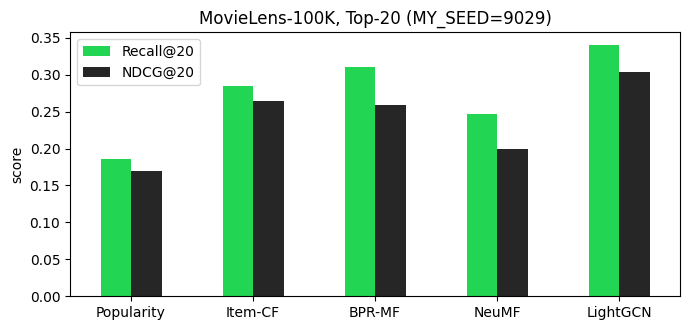

In [31]:
res_df = pd.DataFrame(results).T
display(res_df.style.format("{:.4f}").highlight_max(color="#D3F7DD"))

ax = res_df.plot.bar(figsize=(7, 3.4), color=["#22D654", "#262626"], rot=0)
ax.set_title("MovieLens-100K, Top-%d (MY_SEED=%s)" % (TOPK, MY_SEED)); ax.set_ylabel("score")
plt.tight_layout(); plt.show()

#### 👀 7-1. 내 시드의 사용자에게 무엇이 추천됐는지 보기

In [32]:
show_u = sorted(test_items.keys())[MY_SEED % len(test_items)]
print("사용자 %d 가 학습 때 본 영화 (일부):" % show_u, [idx2title[i] for i in list(train_items[show_u])[:6]])
print("숨겨둔 정답 (test):", [idx2title[i] for i in test_items[show_u]][:6])
for name, mdl in [("BPR-MF", mf), ("LightGCN", lgcn)]:
    sc = mdl.full_scores(torch.tensor([show_u], device=device))[0].detach().cpu()
    sc[list(train_items[show_u])] = -float("inf")
    top = torch.topk(sc, 5).indices.tolist()
    print("\n[%s] Top-5:" % name)
    for r, i in enumerate(top, 1):
        print("  %d. %s %s" % (r, idx2title[i], "✓ 정답" if i in test_items[show_u] else ""))

사용자 589 가 학습 때 본 영화 (일부): ['Shanghai Triad (Yao a yao yao dao waipo qiao)', 'Big Night', 'Mighty Aphrodite', 'Postino, Il', 'Sense and Sensibility', "Antonia's Line"]
숨겨둔 정답 (test): ['Leaving Las Vegas', 'Cold Comfort Farm', 'Crucible, The', "Young Poisoner's Handbook, The", 'Breaking the Waves']

[BPR-MF] Top-5:
  1. Birdcage, The 
  2. Emma 
  3. Leaving Las Vegas ✓ 정답
  4. Dead Man Walking 
  5. Restoration 

[LightGCN] Top-5:
  1. Leaving Las Vegas ✓ 정답
  2. Dead Man Walking 
  3. Cold Comfort Farm ✓ 정답
  4. Emma 
  5. Welcome to the Dollhouse 


#### 📝 서술형 문제 2
1. 7장의 표에서 다섯 결과(Popularity(인기순), Item-CF, BPR-MF, NeuMF, LightGCN)를 Recall@20 기준으로 순서대로 나열하고 숫자를 인용하세요.
2. **인기순 추천이 생각보다 강하게 나왔다면(또는 약하게 나왔다면)** 그 이유를 1장의 Long-tail 결과와 연결해 설명하세요.
3. 세션 21p는 "잘 튜닝한 MF가 NCF를 이기기도 한다(Rendle et al., 2020)"고 했습니다. 본인 결과에서 BPR-MF와 NeuMF 중 무엇이 더 좋았나요? 같은 epoch, 같은 학습률로 비교한 이 실험이 **공정한 비교인지** 한 가지 이상의 근거로 판단하세요.

--

1.

| 순위 | 모델 | Recall@20 |
|---|---|---|
| 1 | LightGCN | 0.3404 |
| 2 | BPR-MF | 0.3104 |
| 3 | Item-CF | 0.2841 |
| 4 | NeuMF | 0.2469 |
| 5 | Popularity | 0.1857 |


2. 인기순 추천의 Recall@20은 0.1857로 다른 개인화 추천 모델보다 낮았지만, 사용자별 취향을 반영하지 않는 단순한 방법임에도 일정 수준의 성능을 보였다. 이는 인기 상위 20%의 영화가 전체 상호작용의 69.0%를 차지하는 Long-tail 구조와 관련이 있다. 많은 사용자가 소수의 인기 영화를 공통적으로 소비하기 때문에 인기순 추천도 일부 정답을 맞힐 수 있지만, 개인별 선호 차이를 반영하지 못한다는 한계가 있다.

3.BPR-MF의 Recall@20은 0.3104, NeuMF는 0.2469로 BPR-MF가 더 높은 성능을 보였다. 이는 복잡한 신경망 구조가 반드시 더 좋은 추천 성능을 보장하지 않는다는 세션 21페이지의 내용과 일치한다.

두 모델은 동일한 데이터 분할, epoch 수, 학습률, BPR 손실을 사용하므로 기본적인 비교 조건은 통제되었다. 그러나 모델 구조와 파라미터 수가 다르기 때문에 동일한 하이퍼파라미터가 두 모델 모두에 최적이라고 볼 수는 없다. 따라서 더 공정한 비교를 위해서는 모델별 하이퍼파라미터 튜닝과 반복 실험이 필요하다.

#### 📝 서술형 문제 3
LightGCN과 BPR-MF는 학습 파라미터 수가 같습니다(6장 확인 셀 출력 인용). 그런데도 성능이 다르게 나왔다면, 그 차이는 **어디에서** 온 것인가요? 6장의 전파 식과 세션 30p("3층이면 매트릭스(3-hop)의 정보까지 반영")를 연결해 설명하세요.

BPR-MF와 LightGCN의 파라미터 수는 152,896개로 같지만, Recall@20은 각각 0.3104, 0.3404로 LightGCN이 더 높았다. MF는 사용자와 아이템의 임베딩을 직접 학습하는 반면, LightGCN은 Message Passing으로 이웃 정보를 전파한다. 층을 쌓을수록 더 먼 이웃의 정보가 반영되므로, 3층에서는 '가빈 → 인터스텔라 → 철수 → 매트릭스' 같은 3-hop 관계까지 활용할 수 있다는 차이가 있다.

# 🔍 Part B. 세션의 주장을 검증하기 (심화 선택)

> ⚠️ 아래 실험은 **세션 슬라이드와 다른 결과가 나올 수 있습니다.** 그래도 그대로 보고하고 원인을 추론하세요.
> 시간 여유가 있다면 `MY_SEED`를 바꿔 한두 번 더 돌려 보고, 결론이 시드에 따라 흔들리는지도 확인하면 좋습니다.

### 🧱 8. 층은 깊을수록 좋을까? - 층 수 실험 & Over-smoothing 측정

세션 41p는 "Gowalla 실험에서는 3층 이후 개선이 작았다"고 했습니다. 이 데이터에서는 어떨까요?
**0층**은 전파가 없으므로 사실상 **BPR-MF와 같은 모델**입니다.

#### ✏️ ===== TODO 11 =====
Over-smoothing을 숫자로 재기 위해, 벡터들이 서로 얼마나 비슷해졌는지 **평균 cosine 유사도**를 구하는 함수를 완성하세요.

0층: {'Recall@20': 0.2993515909531947, 'NDCG@20': 0.25217358120554456} (4초)
1층: {'Recall@20': 0.34726500222943424, 'NDCG@20': 0.302759349145675} (5초)
2층: {'Recall@20': 0.3559629936837283, 'NDCG@20': 0.31475448691262287} (10초)
3층: {'Recall@20': 0.3415935166532904, 'NDCG@20': 0.30478107882994826} (10초)
4층: {'Recall@20': 0.3292148449193618, 'NDCG@20': 0.29333233445088774} (12초)


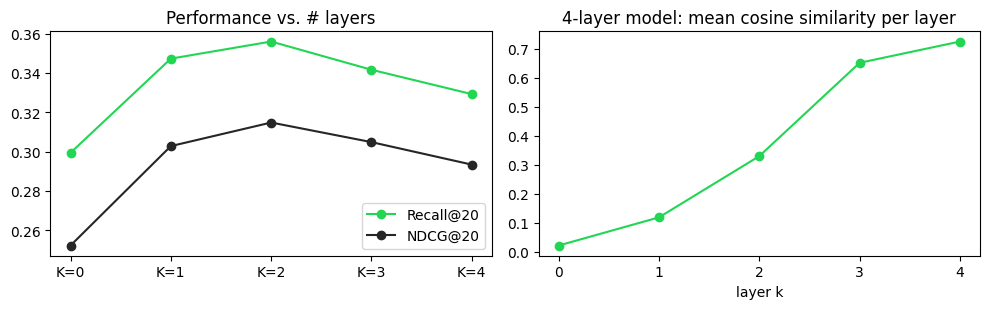

,Recall@20,NDCG@20
K=0,0.2994,0.2522
K=1,0.3473,0.3028
K=2,0.3560,0.3148
K=3,0.3416,0.3048
K=4,0.3292,0.2933


In [33]:
def mean_cosine(E, n_sample=500):
    idx = torch.randperm(E.size(0))[:n_sample]
    # ===== TODO 11 =====
    # 힌트: 행마다 L2 정규화 → 내적 행렬 → 대각선(자기 자신)을 뺀 나머지의 평균
    E_sample = F.normalize(E[idx], p=2, dim=-1)
    sim = E_sample @ E_sample.T

    n = E_sample.size(0)
    return ((sim.sum() - sim.diag().sum()) / (n * (n - 1))).item()   # TODO: 여기에 코드를 작성하세요
    # ==================


layer_res, cos_by_layer = {}, None
for K in [0, 1, 2, 3, 4]:
    t0 = time.time()
    m, _ = train_model(LightGCN(n_layers=K), verbose=False)
    layer_res["K=%d" % K] = evaluate(m.full_scores)
    print("%d층: %s (%.0f초)" % (K, layer_res["K=%d" % K], time.time() - t0))
    if K == 4:
        with torch.no_grad():
            cos_by_layer = [mean_cosine(E.detach().cpu()) for E in m.layer_embs()]

layer_df = pd.DataFrame(layer_res).T
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
layer_df.plot(ax=axs[0], marker="o", color=["#22D654", "#262626"]); axs[0].set_title("Performance vs. # layers")
axs[1].plot(range(5), cos_by_layer, marker="o", color="#22D654"); axs[1].set_xticks(range(5))
axs[1].set_title("4-layer model: mean cosine similarity per layer"); axs[1].set_xlabel("layer k")
plt.tight_layout(); plt.show()
display(layer_df.style.format("{:.4f}"))

#### 📝 서술형 문제 4
1. 본인 결과에서 성능이 가장 좋았던 층 수와, 0층(≈ MF) 대비 향상 폭을 인용하세요.
2. 오른쪽 그래프에서 층이 깊어질수록 평균 cosine 유사도가 어떻게 변했나요? 이것이 세션 31p의 Over-smoothing과 같은 현상인지 판단하세요.
3. LightGCN이 마지막 층만 쓰지 않고 **층 평균**을 쓰는 이유를, 이 두 그래프를 근거로 설명하세요.

(여기에 답)

### ⚖️ 9. W와 σ를 다시 넣으면? - LightGCN vs NGCF 스타일

세션 38p: "ID와 상호작용만 쓰는 협업 필터링 **실험에서는** W와 σ를 뺀 쪽이 더 나았다."
LightGCN의 매 층에 **선형 변환 W와 활성화 함수 σ(LeakyReLU)** 를 다시 넣어 직접 비교합니다.

#### ✏️ ===== TODO 12 =====

In [34]:
class LightGCNWithW(LightGCN):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__(n_layers)
        self.W = nn.ModuleList([nn.Linear(EMB_DIM, EMB_DIM) for _ in range(n_layers)])

    def layer_embs(self):
        # ===== TODO 12 =====
        # 힌트: 직전 층 벡터를 전파한 뒤(torch.sparse.mm) → self.W[k] 로 변환 → F.leaky_relu(…, 0.2) 를 적용하세요.
        layers = [self.emb.weight]   # TODO: 여기에 코드를 작성하세요

        for k in range(self.n_layers):
            h = torch.sparse.mm(self.A, layers[-1])
            h = F.leaky_relu(self.W[k](h), negative_slope=0.2)
            layers.append(h)
        return layers
        # ==================


t0 = time.time()
lgcn_w, _ = train_model(LightGCNWithW())
results_w = {"LightGCN": results["LightGCN"], "LightGCN + W + sigma": evaluate(lgcn_w.full_scores)}
display(pd.DataFrame(results_w).T.style.format("{:.4f}"))
print("(%.0f초)" % (time.time() - t0))

epoch  10 | loss 0.2725 | Recall@20 0.2454 | NDCG@20 0.2213
epoch  20 | loss 0.2154 | Recall@20 0.2879 | NDCG@20 0.2565
epoch  30 | loss 0.1947 | Recall@20 0.3015 | NDCG@20 0.2654
epoch  40 | loss 0.1781 | Recall@20 0.3192 | NDCG@20 0.2856
epoch  50 | loss 0.1671 | Recall@20 0.3188 | NDCG@20 0.2809


,Recall@20,NDCG@20
LightGCN,0.3404,0.3042
LightGCN + W + sigma,0.3188,0.2809


(11초)


#### 📝 서술형 문제 5
1. W와 σ를 넣은 모델이 더 좋았나요, 나빴나요? 숫자를 인용하세요.
2. 결과가 세션 38p와 **같았다면** 그 이유를, **달랐다면** 가능한 원인(epoch 수, 학습률, 데이터 크기 등)을 추론하세요.
3. 만약 영화에 장르, 줄거리 같은 **콘텐츠 특징**이 있었다면, W의 역할이 어떻게 달라질 수 있을지 생각해 보세요.

--
1. 기본 LightGCN의 Recall@20은 0.3404, W와 활성화 함수를 추가한 모델은 0.3188로 기본 모델이 더 높았다.

2. 이는 ID 임베딩만 사용하는 협업 필터링에서 W와 활성화 함수를 제거하는 것이 오히려 유리할 수 있다는 세션 내용과 일치한다. 추가적인 변환이 반드시 성능 향상으로 이어지는 것은 아니다.

3. 장르나 줄거리 등의 콘텐츠 특징이 추가된다면 W는 다양한 특징을 추천에 유용한 잠재 표현으로 변환하는 역할을 할 수 있어 유용할 것이다.

### 📈 10. 정규화는 인기 편향을 줄일까? - 추천 결과의 인기도 분석

세션 39p는 "차수에 따라 정보 전달 크기를 조절할 뿐, 이것만으로 인기 편향이 해결되지는 않는다"고 했습니다. **직접 재 봅시다.**

#### ✏️ ===== TODO 13 =====
모델별 추천 목록(사용자당 Top-20)에서 두 가지를 구하세요.
- **평균 인기도**: 추천된 영화들의 학습 데이터 상호작용 수(`pop`) 평균
- **Long-tail 비율**: 추천된 영화 중 인기 상위 20%에 **속하지 않는** 영화의 비율

,avg_popularity,longtail_ratio
Popularity,227.9,0.0%
BPR-MF,125.7,14.7%
NeuMF,111.0,20.6%
LightGCN,148.8,6.2%


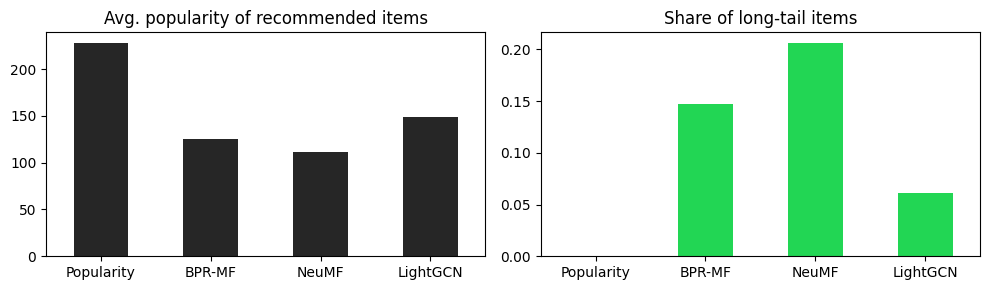

In [35]:
head_items = set(torch.argsort(pop, descending=True)[: int(n_items * 0.2)].tolist())

def popularity_stats(rec_lists):
    all_rec = [i for lst in rec_lists.values() for i in lst]
    # ===== TODO 13 =====
    # 힌트: all_rec 의 각 영화에 대해 pop[i] 평균, 그리고 head_items 에 없는 영화의 비율
    avg_pop = np.mean([pop[i].item() for i in all_rec])      # TODO: 여기에 코드를 작성하세요
    tail_ratio = np.mean([i not in head_items for i in all_rec])   # TODO: 여기에 코드를 작성하세요
    # ==================
    return {"avg_popularity": avg_pop, "longtail_ratio": tail_ratio}


bias = {}
for name, fn in [("Popularity", lambda users: pop.to(device).unsqueeze(0).repeat(len(users), 1)),
                 ("BPR-MF", mf.full_scores), ("NeuMF", neumf.full_scores), ("LightGCN", lgcn.full_scores)]:
    _, lists = evaluate(fn, return_lists=True)
    bias[name] = popularity_stats(lists)
bias_df = pd.DataFrame(bias).T
display(bias_df.style.format({"avg_popularity": "{:.1f}", "longtail_ratio": "{:.1%}"}))

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
bias_df["avg_popularity"].plot.bar(ax=axs[0], color="#262626", rot=0, title="Avg. popularity of recommended items")
bias_df["longtail_ratio"].plot.bar(ax=axs[1], color="#22D654", rot=0, title="Share of long-tail items")
plt.tight_layout(); plt.show()

#### 📝 서술형 문제 6
1. LightGCN의 추천은 BPR-MF보다 인기작 쪽으로 더 치우쳤나요, 덜 치우쳤나요? 두 지표를 인용하세요.
2. 결과를 근거로 "LightGCN의 정규화는 인기 편향을 해결한다"는 문장이 맞는지 판단하세요.
3. 정확도(7장)와 다양성(10장) 사이에 **트레이드오프**가 보였다면, 실제 서비스라면 어떤 기준으로 모델을 고르겠는지 한두 문장으로 적으세요.

--

1.
| 모델 | 평균 인기도 | Long-tail 비율 |
|---|---:|---:|
| Popularity | 227.9 | 0.0% |
| BPR-MF | 125.7 | 14.7% |
| NeuMF | 111.0 | 20.6% |
| LightGCN | 148.8 | 6.2% |

  LightGCN은 BPR-MF보다 평균 인기도가 높고 Long-tail 비율은 낮아 인기 영화에 더 편향되었다.

2. LightGCN의 대칭 정규화는 연결 수에 따른 정보 전달 가중치를 조절하지만, 인기 편향을 직접 제거하지는 않는다. 실제로 LightGCN의 Long-tail 비율은 6.2%로 BPR-MF보다 낮았다.

3. LightGCN은 Recall@20이 0.3404로 가장 높지만 Long-tail 비율은 6.2%에 불과했다. 따라서 실제 서비스에서는 Recall뿐 아니라 추천 다양성과 Long-tail 비율도 함께 고려해야 한다.

#### 🤔 회고

Part A에서 겪은 어려움과 해결 과정을 3-5문장으로 적습니다. 끝까지 헷갈린 개념 1-3개도 함께: 미지의 정보가 많아서 코드 짜는데 어려움이 있음을 체감할 수 있었다.

Part B(심화 선택)를 진행했다면, 세션 내용과 **다르게 나온 결과**와 그로부터 배운 점을 이어서 적어도 좋습니다: (여기에 답)

#### ⚙️ 생성형 AI 활용 (비판적 사용)

AI는 **검산기, 설명 도우미**로 활용하고 최종 판단은 본인이 합니다.

- **어디에 썼나** (PyTorch 문법 디버깅, 개념 설명, 에러 해석 등 구체적으로): 써있는 변수만 했더니 오류가

- **AI가 이 실험에는 틀린 답을 준 사례**
  본인이 겪은 사례와, 그것을 **어떻게 알아채고 고쳤는지**(본인 출력값과 대조 / 공식 문서 확인 / 직접 실험) 적으세요: (여기에 답)

- **실제 대화 내역** 붙여넣기:

```
Q. \---------------------------------------------------------------------------&#x20;
AssertionError                            Traceback (most recent call last)&#x20;
[/tmp/ipykernel_349/4136230643.py](https://localhost:8080/#) in \<cell line: 0>()&#x20;**&#x20;    21** # ✅ 확인&#x20;**&#x20;    22** u, p, n = sample_batch(512) ---> 23 assert all(n[k].item() not in train_items[u[k].item()] for k in range(512)), "neg 중에 사용자가 본 영화가 섞여 있습니다."&#x20;**&#x20;    24** assert abs(bpr_loss(torch.tensor([2.0]), torch.tensor([0.0])).item() - 0.1269) < 1e-3, "BPR 손실 식을 확인하세요."&#x20;**&#x20;    25** print("✅ 통과") &#x20;
AssertionError: neg 중에 사용자가 본 영화가 섞여 있습니다.

A. 이 오류는 TODO 5의 Negative Sampling에서 사용자가 이미 본 영화가 `neg`에 포함되었기 때문이야.

기존 TODO 5 코드를 아래 코드로 교체해 봐.


# ===== TODO 5 =====neg = torch.randint(0, n_items, (batch_size,))invalid = train_mask[users, neg]while invalid.any().item():    neg[invalid] = torch.randint(        0, n_items, (invalid.sum().item(),)    )    invalid = train_mask[users, neg]# ==================


중요한 수정 부분은 다음 줄이야.


invalid = train_mask[users, neg]


기존 코드에서는 `invalid`를 반복문 밖에서 한 번만 계산했기 때문에, 다시 뽑은 영화가 여전히 학습 기록에 포함되어 있어도 이를 확인하지 못했어.

수정한 코드는 재추출할 때마다 `invalid`를 갱신하므로, 모든 Negative Sample이 조건을 만족할 때까지 반복해.

TODO 5가 포함된 셀을 다시 실행한 뒤, 아래 확인 셀을 실행하면 돼.

u, p, n = sample_batch(512)assert all(    n[k].item() not in train_items[u[k].item()]    for k in range(512))print("✅ Negative Sampling 통과")
```

- 마지막 한 문장: **AI가 대신할 수 없었던 나만의 판단**은 무엇이었나요? (여기에 답)

#### 📚 참고 자료

**Part A**
- BPR: Rendle et al., [BPR: Bayesian Personalized Ranking from Implicit Feedback](https://arxiv.org/abs/1205.2618) (UAI 2009)
- NCF: He et al., [Neural Collaborative Filtering](https://arxiv.org/abs/1708.05031) (WWW 2017)
- LightGCN: He et al., [LightGCN: Simplifying and Powering Graph Convolution Network for Recommendation](https://arxiv.org/abs/2002.02126) (SIGIR 2020)
- MovieLens: Harper & Konstan, [The MovieLens Datasets: History and Context](https://dl.acm.org/doi/10.1145/2827872) (ACM TiiS 2015)

**Part B**
- NGCF: Wang et al., [Neural Graph Collaborative Filtering](https://arxiv.org/abs/1905.08108) (SIGIR 2019)
- MF vs NCF 재검증: Rendle et al., [Neural Collaborative Filtering vs. Matrix Factorization Revisited](https://arxiv.org/abs/2005.09683) (RecSys 2020)
- 강의 자료: [Stanford CS224W](https://web.stanford.edu/class/cs224w/)